## EN3160 – Assignment 3: Neural Networks

**Name:** Deshan W.U.  
**Index Number:** 230130E

In [1]:
import torch
import torch .nn as nn
import torch .optim as optim
import torchvision
import torchvision .transforms as transforms
import matplotlib . pyplot as plt

Question 1

In [4]:
# 1. Data loading
transform = transforms.Compose(
    [transforms.ToTensor(),
     transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))])

batch_size = 50

trainset = torchvision.datasets.CIFAR10(root='./data', train=True,
                                        download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size,
                                          shuffle=True, num_workers=2)

testset = torchvision.datasets.CIFAR10(root='./data', train=False,
                                       download=True, transform=transform)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size,
                                         shuffle=False, num_workers=2)

classes = ('plane', 'car', 'bird', 'cat', 'deer',
           'dog', 'frog', 'horse', 'ship', 'truck')



100%|██████████| 170M/170M [1:49:19<00:00, 26.0kB/s]  


Extracting ./data\cifar-10-python.tar.gz to ./data
Files already downloaded and verified


Epoch 1/10, Loss: 1.8097347614765167
Epoch 2/10, Loss: 1.679225182056427
Epoch 3/10, Loss: 1.6212337262630463
Epoch 4/10, Loss: 1.5752793266773224
Epoch 5/10, Loss: 1.5363085768222808
Epoch 6/10, Loss: 1.5035136926174164
Epoch 7/10, Loss: 1.471570742726326
Epoch 8/10, Loss: 1.4460643712282182
Epoch 9/10, Loss: 1.4205351933836936
Epoch 10/10, Loss: 1.3999517545104028


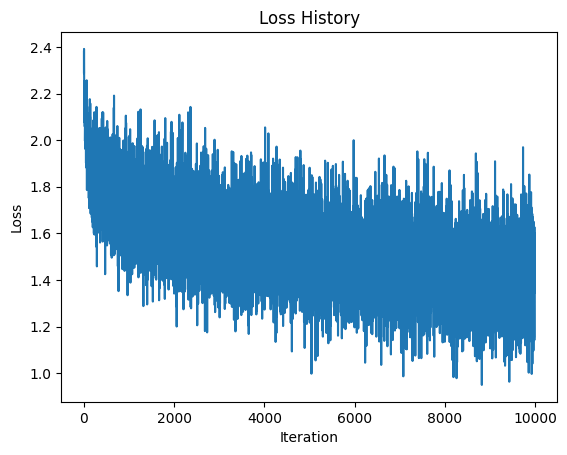

Training accuracy: 53.20%
Test accuracy: 47.72%


In [5]:
# 2. Define Network Parameters
Din = 3 * 32 * 32  # Input size (flattened CIFAR-10 image size)
H = 100            # Number of nodes in the middle layer
K = 10             # Output size (number of classes in CIFAR-10)
std = 1e-2         # larger init std, needed for the hidden layer
 
# Initialize weights and biases
w1 = torch.randn(Din, H) * std       
b1 = torch.zeros(H)
w2 = torch.randn(H, K) * std * 10    
b2 = torch.zeros(K)
 
# Hyperparameters
iterations = 10    #  10 epochs
lr = 1e-1          # learning rate suited to cross-entropy
lr_decay = 0.9     # Learning rate decay
reg = 0            # Regularization
 
loss_history = []
 
# 3. Training Loop
for t in range(iterations):
    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # Get inputs and labels
        inputs, labels = data
        Ntr = inputs.shape[0]  # Batch size
        x_train = inputs.view(Ntr, -1)  # Flatten input to (Ntr, Din)
        y_train_onehot = nn.functional.one_hot(labels, K).float()  # Convert labels to one-hot
 
        # Forward pass
        h = torch.sigmoid(x_train.mm(w1) + b1)   # middle layer, sigmoid
        y_pred = h.mm(w2) + b2                   # Output layer
        # softmax for cross-entropy (max subtracted for stability)
        e = torch.exp(y_pred - y_pred.max(dim=1, keepdim=True).values)
        p = e / e.sum(dim=1, keepdim=True)
 
        # Loss calculation (Cross-entropy with regularization)
        loss = -(1 / Ntr) * torch.sum(y_train_onehot * torch.log(p + 1e-12)) \
               + reg * (torch.sum(w1 ** 2) + torch.sum(w2 ** 2))
        loss_history.append(loss.item())
        running_loss += loss.item()
 
        # Backpropagation
        dy_pred = (1.0 / Ntr) * (p - y_train_onehot)    # softmax + cross-entropy gradient
        dw2 = h.t().mm(dy_pred) + reg * w2
        db2 = dy_pred.sum(dim=0)
        dh = dy_pred.mm(w2.t())                         # back through middle layer
        dz1 = dh * h * (1 - h)                          # sigmoid derivative
        dw1 = x_train.t().mm(dz1) + reg * w1
        db1 = dz1.sum(dim=0)
 
        # Parameter update
        w1 -= lr * dw1
        b1 -= lr * db1
        w2 -= lr * dw2
        b2 -= lr * db2
 
    # Print loss for every epoch
    if t % 1 == 0:
        print(f"Epoch {t + 1}/{iterations}, Loss: {running_loss / len(trainloader)}")
 
    # Learning rate decay
    lr *= lr_decay
 
# 4. Plotting the Loss History
plt.plot(loss_history)
plt.title("Loss History")
plt.xlabel("Iteration")
plt.ylabel("Loss")
plt.show()
 
# 5. Calculate Accuracy on Training Set
correct_train = 0
total_train = 0
with torch.no_grad():
    for data in trainloader:
        inputs, labels = data
        Ntr = inputs.shape[0]
        x_train = inputs.view(Ntr, -1)
        y_train_onehot = nn.functional.one_hot(labels, K).float()
 
        # Forward pass 
        h = torch.sigmoid(x_train.mm(w1) + b1)
        y_train_pred = h.mm(w2) + b2
 
        predicted_train = torch.argmax(y_train_pred, dim=1)
        total_train += labels.size(0)
        correct_train += (predicted_train == labels).sum().item()
 
train_acc = 100 * correct_train / total_train
print(f"Training accuracy: {train_acc:.2f}%")
 
# 6. Calculate Accuracy on Test Set
correct_test = 0
total_test = 0
with torch.no_grad():
    for data in testloader:
        inputs, labels = data
        Nte = inputs.shape[0]
        x_test = inputs.view(Nte, -1)
        y_test_onehot = nn.functional.one_hot(labels, K).float()
 
        # Forward pass 
        h = torch.sigmoid(x_test.mm(w1) + b1)
        y_test_pred = h.mm(w2) + b2
 
        predicted_test = torch.argmax(y_test_pred, dim=1)
        total_test += labels.size(0)
        correct_test += (predicted_test == labels).sum().item()
 
test_acc = 100 * correct_test / total_test
print(f"Test accuracy: {test_acc:.2f}%")
 

Question 2

In [8]:
# Q2(a)
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(0)
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])   # MNIST mean / std
#Data loading
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))])   # MNIST mean / std
 
batch_size = 64
trainset = torchvision.datasets.MNIST('./data', train=True, download=True, transform=transform)
testset = torchvision.datasets.MNIST('./data', train=False, download=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=batch_size, shuffle=True, num_workers=2)
testloader = torch.utils.data.DataLoader(testset, batch_size=batch_size, shuffle=False, num_workers=2)

# Model: LeNet-5
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv2d(1, 6, kernel_size=5, padding=2),   
            nn.Tanh(),
            nn.AvgPool2d(2, 2),                          
            nn.Conv2d(6, 16, kernel_size=5),             
            nn.Tanh(),
            nn.AvgPool2d(2, 2))                          
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(16 * 5 * 5, 120), nn.Tanh(),
            nn.Linear(120, 84), nn.Tanh(),
            nn.Linear(84, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(model, loader, criterion):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_targets.append(y.cpu())
    return (total_loss / total, 100.0 * correct / total,
            torch.cat(all_preds), torch.cat(all_targets))


#Training 
epochs = 10
lr = 1e-3

model = LeNet5().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(epochs):
    model.train()
    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    tr_loss, tr_acc, _, _ = evaluate(model, trainloader, criterion)
    te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
    history['train_loss'].append(tr_loss)
    history['test_loss'].append(te_loss)
    history['train_acc'].append(tr_acc)
    history['test_acc'].append(te_acc)
    print(f"Epoch {epoch + 1}/{epochs} | Train loss {tr_loss:.4f}, acc {tr_acc:.2f}% "
          f"| Test loss {te_loss:.4f}, acc {te_acc:.2f}%")

# Results 
_, final_train_acc, _, _ = evaluate(model, trainloader, criterion)
_, final_test_acc, test_preds, test_targets = evaluate(model, testloader, criterion)
print(f"\nLeNet-5 final training accuracy: {final_train_acc:.2f}%")
print(f"LeNet-5 final test accuracy:     {final_test_acc:.2f}%")
print("Parameters:", sum(p.numel() for p in model.parameters()))

# Save for plots and confusion matrix
torch.save({'history': history, 'preds': test_preds, 'targets': test_targets},
           'lenet5_results.pt')

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 9.91M/9.91M [00:13<00:00, 714kB/s] 


Extracting ./data\MNIST\raw\train-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 28.9k/28.9k [00:00<00:00, 97.0kB/s]


Extracting ./data\MNIST\raw\train-labels-idx1-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 1.65M/1.65M [00:02<00:00, 619kB/s] 


Extracting ./data\MNIST\raw\t10k-images-idx3-ubyte.gz to ./data\MNIST\raw

Failed to download (trying next):
HTTP Error 404: Not Found



100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]


Extracting ./data\MNIST\raw\t10k-labels-idx1-ubyte.gz to ./data\MNIST\raw

Epoch 1/10 | Train loss 0.0866, acc 97.47% | Test loss 0.0880, acc 97.38%
Epoch 2/10 | Train loss 0.0505, acc 98.47% | Test loss 0.0584, acc 98.25%
Epoch 3/10 | Train loss 0.0399, acc 98.80% | Test loss 0.0585, acc 98.28%
Epoch 4/10 | Train loss 0.0313, acc 99.00% | Test loss 0.0484, acc 98.47%
Epoch 5/10 | Train loss 0.0236, acc 99.28% | Test loss 0.0438, acc 98.62%
Epoch 6/10 | Train loss 0.0191, acc 99.38% | Test loss 0.0393, acc 98.63%
Epoch 7/10 | Train loss 0.0194, acc 99.39% | Test loss 0.0457, acc 98.59%
Epoch 8/10 | Train loss 0.0170, acc 99.45% | Test loss 0.0434, acc 98.75%
Epoch 9/10 | Train loss 0.0105, acc 99.70% | Test loss 0.0412, acc 98.62%
Epoch 10/10 | Train loss 0.0130, acc 99.57% | Test loss 0.0441, acc 98.72%

LeNet-5 final training accuracy: 99.57%
LeNet-5 final test accuracy:     98.72%
Parameters: 61706


In [9]:
# Q2(b): Modern small CNN (3 conv layers + BatchNorm + Dropout) on MNIST
# Model 
class SmallCNN(nn.Module):
    def __init__(self, p_drop=0.3):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(
                nn.Conv2d(cin, cout, kernel_size=3, padding=1),
                nn.BatchNorm2d(cout),
                nn.ReLU(),
                nn.MaxPool2d(2))
        self.features = nn.Sequential(
            block(1, 32),    
            block(32, 64),    
            block(64, 128))   
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p_drop),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(p_drop),
            nn.Linear(128, 10))

    def forward(self, x):
        return self.classifier(self.features(x))

def evaluate(model, loader, criterion):
    model.eval()   # disables dropout, uses BatchNorm running statistics
    total_loss, correct, total = 0.0, 0, 0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += criterion(out, y).item() * y.size(0)
            pred = out.argmax(dim=1)
            correct += (pred == y).sum().item()
            total += y.size(0)
            all_preds.append(pred.cpu())
            all_targets.append(y.cpu())
    return (total_loss / total, 100.0 * correct / total,
            torch.cat(all_preds), torch.cat(all_targets))

# Training 
epochs = 10
lr = 1e-3

model = SmallCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=lr)

history = {'train_loss': [], 'test_loss': [], 'train_acc': [], 'test_acc': []}

for epoch in range(epochs):
    model.train()
    for x, y in trainloader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()

    tr_loss, tr_acc, _, _ = evaluate(model, trainloader, criterion)
    te_loss, te_acc, _, _ = evaluate(model, testloader, criterion)
    history['train_loss'].append(tr_loss)
    history['test_loss'].append(te_loss)
    history['train_acc'].append(tr_acc)
    history['test_acc'].append(te_acc)
    print(f"Epoch {epoch + 1}/{epochs} | Train loss {tr_loss:.4f}, acc {tr_acc:.2f}% "
          f"| Test loss {te_loss:.4f}, acc {te_acc:.2f}%")

# Final results 
_, final_train_acc, _, _ = evaluate(model, trainloader, criterion)
_, final_test_acc, test_preds, test_targets = evaluate(model, testloader, criterion)
print(f"\nSmall CNN final training accuracy: {final_train_acc:.2f}%")
print(f"Small CNN final test accuracy:     {final_test_acc:.2f}%")
print("Parameters:", sum(p.numel() for p in model.parameters()))

# Save for plots and confusion matrix
torch.save({'history': history, 'preds': test_preds, 'targets': test_targets},
           'smallcnn_results.pt')

Epoch 1/10 | Train loss 0.0472, acc 98.47% | Test loss 0.0498, acc 98.53%
Epoch 2/10 | Train loss 0.0785, acc 97.53% | Test loss 0.0789, acc 97.39%
Epoch 3/10 | Train loss 0.0206, acc 99.34% | Test loss 0.0278, acc 99.11%
Epoch 4/10 | Train loss 0.0245, acc 99.24% | Test loss 0.0321, acc 99.04%
Epoch 5/10 | Train loss 0.0144, acc 99.56% | Test loss 0.0247, acc 99.26%
Epoch 6/10 | Train loss 0.0100, acc 99.66% | Test loss 0.0222, acc 99.31%
Epoch 7/10 | Train loss 0.0089, acc 99.70% | Test loss 0.0224, acc 99.39%
Epoch 8/10 | Train loss 0.0085, acc 99.75% | Test loss 0.0238, acc 99.20%
Epoch 9/10 | Train loss 0.0067, acc 99.78% | Test loss 0.0276, acc 99.18%
Epoch 10/10 | Train loss 0.0055, acc 99.83% | Test loss 0.0179, acc 99.40%

Small CNN final training accuracy: 99.83%
Small CNN final test accuracy:     99.40%
Parameters: 241994


C:\Users\ASUS\AppData\Local\Temp\ipykernel_11084\515064981.py:6: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  'LeNet-5': torch.load('lenet5_results.pt'),
C:\Users\ASUS\AppD

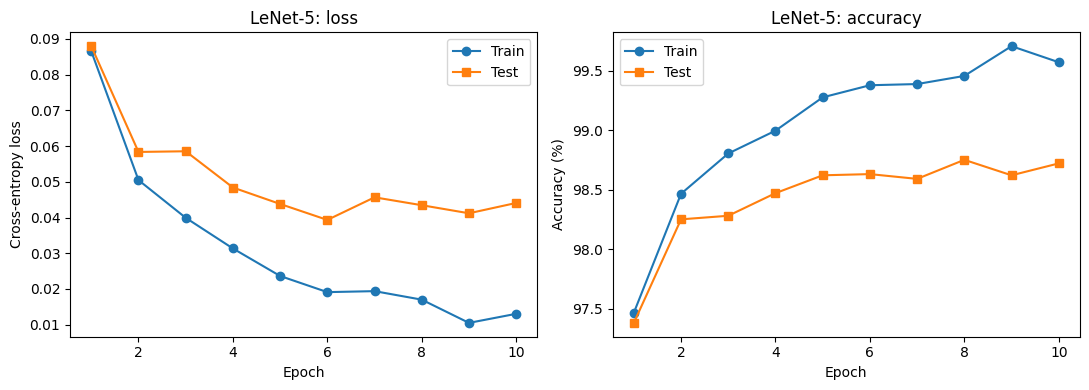

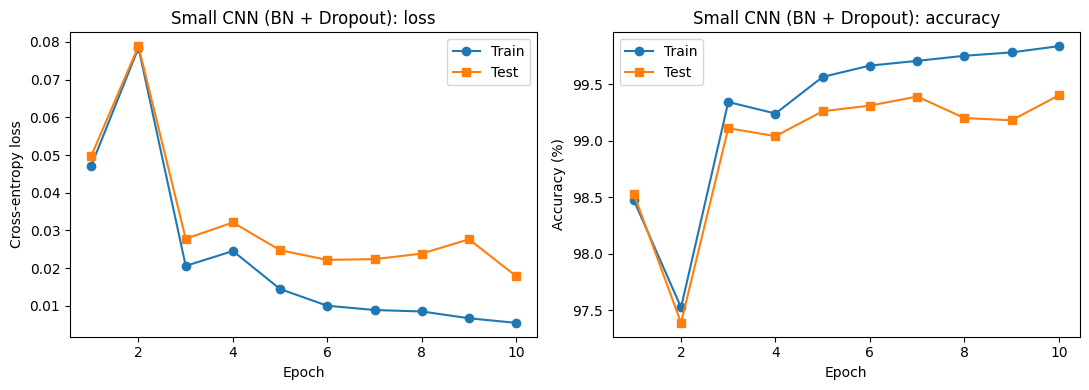

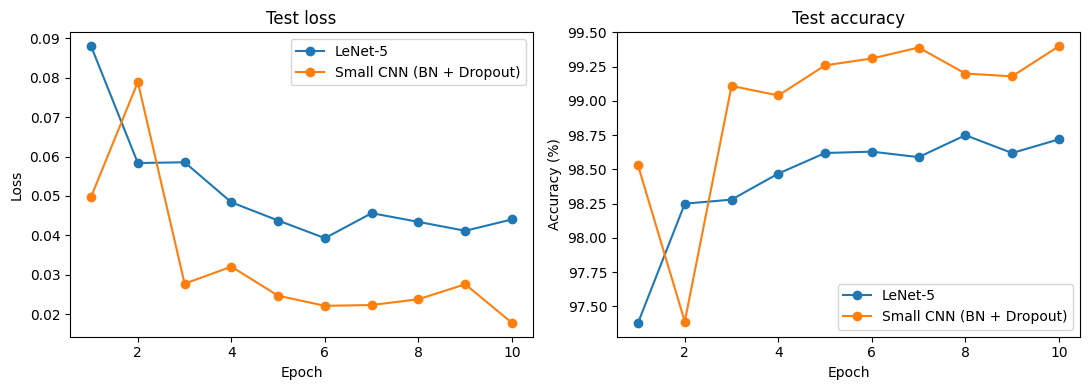

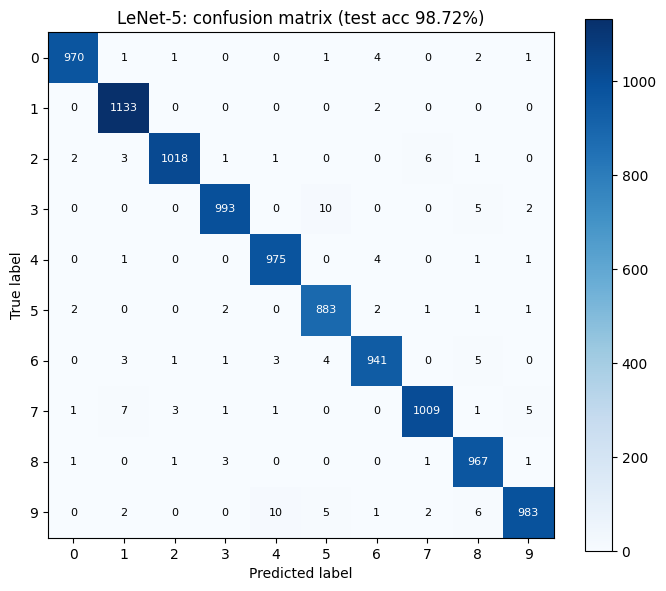

LeNet-5: most common mistakes
  true 9 -> predicted 4: 10 times
  true 3 -> predicted 5: 10 times
  true 7 -> predicted 1: 7 times


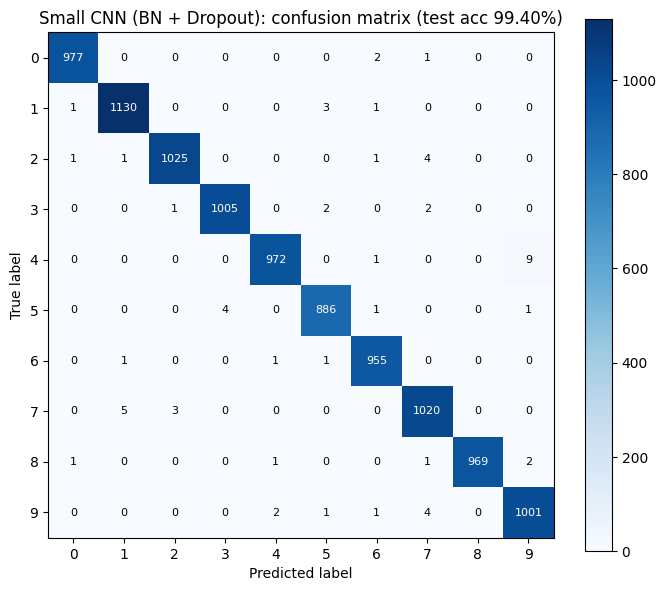

Small CNN (BN + Dropout): most common mistakes
  true 4 -> predicted 9: 9 times
  true 7 -> predicted 1: 5 times
  true 2 -> predicted 7: 4 times


In [10]:
# Q2(c): Per-epoch accuracy/loss plots and test-set confusion matrices
import torch
import matplotlib.pyplot as plt

results = {
    'LeNet-5': torch.load('lenet5_results.pt'),
    'Small CNN (BN + Dropout)': torch.load('smallcnn_results.pt'),
}
class_names = [str(i) for i in range(10)]

# Per-epoch curves 
for name, res in results.items():
    h = res['history']
    epochs = range(1, len(h['train_loss']) + 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    ax[0].plot(epochs, h['train_loss'], marker='o', label='Train')
    ax[0].plot(epochs, h['test_loss'], marker='s', label='Test')
    ax[0].set_title(f'{name}: loss')
    ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Cross-entropy loss'); ax[0].legend()

    ax[1].plot(epochs, h['train_acc'], marker='o', label='Train')
    ax[1].plot(epochs, h['test_acc'], marker='s', label='Test')
    ax[1].set_title(f'{name}: accuracy')
    ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()

    plt.tight_layout()
    plt.show()

#  Side-by-side comparison 
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for name, res in results.items():
    h = res['history']
    epochs = range(1, len(h['test_loss']) + 1)
    ax[0].plot(epochs, h['test_loss'], marker='o', label=name)
    ax[1].plot(epochs, h['test_acc'], marker='o', label=name)
ax[0].set_title('Test loss'); ax[0].set_xlabel('Epoch'); ax[0].set_ylabel('Loss'); ax[0].legend()
ax[1].set_title('Test accuracy'); ax[1].set_xlabel('Epoch'); ax[1].set_ylabel('Accuracy (%)'); ax[1].legend()
plt.tight_layout()
plt.show()

# Confusion matrices 
def confusion_matrix(preds, targets, num_classes=10):
    cm = torch.zeros(num_classes, num_classes, dtype=torch.int64)
    for t, p in zip(targets, preds):
        cm[t, p] += 1
    return cm

for name, res in results.items():
    cm = confusion_matrix(res['preds'], res['targets'])
    acc = 100.0 * cm.diag().sum().item() / cm.sum().item()

    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm.numpy(), cmap='Blues')
    ax.set_xticks(range(10)); ax.set_xticklabels(class_names)
    ax.set_yticks(range(10)); ax.set_yticklabels(class_names)
    ax.set_xlabel('Predicted label'); ax.set_ylabel('True label')
    ax.set_title(f'{name}: confusion matrix (test acc {acc:.2f}%)')
    thresh = cm.max().item() / 2
    for i in range(10):
        for j in range(10):
            ax.text(j, i, int(cm[i, j]), ha='center', va='center', fontsize=8,
                    color='white' if cm[i, j] > thresh else 'black')
    fig.colorbar(im, ax=ax)
    plt.tight_layout()
    plt.show()

    # Most confused pairs
    off = cm.clone()
    off.fill_diagonal_(0)
    top = torch.topk(off.flatten(), 3)
    print(f'{name}: most common mistakes')
    for val, idx in zip(top.values, top.indices):
        print(f'  true {idx.item() // 10} -> predicted {idx.item() % 10}: {val.item()} times')